# Session 1 — Notebook de prise en main : Python pour l'IA
**Formation IA pour actuariat vie — Allianz × Quant AI Lab**

**Objectif :** lire et exécuter un notebook simple ; charger un portefeuille vie synthétique,
calculer un taux de rachat par segment, détecter des valeurs manquantes, produire un graphique.

**Durée :** fin de session 1 (~30 min) · aucune expérience Python requise — exécutez cellule par cellule (Maj+Entrée).

## 1. Les bases utiles, en 5 minutes

Exécutez chaque cellule et **lisez la sortie** : c'est tout l'exercice.

In [1]:
# Variables et typage dynamique : Python devine le type
taux_rachat = 0.062        # float
produit = "multi_support"  # chaîne
nb_contrats = 5000         # entier
print(type(taux_rachat), type(produit), type(nb_contrats))

<class 'float'> <class 'str'> <class 'int'>


In [2]:
# Listes et dictionnaires : les deux structures à connaître
segments = ["grand_public", "affluent", "prive"]
effectifs = {"grand_public": 3100, "affluent": 1600, "prive": 300}
print("segments :", segments)
print("effectif du segment prive :", effectifs["prive"])

segments : ['grand_public', 'affluent', 'prive']
effectif du segment prive : 300


In [3]:
# Fonction : un bloc réutilisable et testable
def taux(n_rachats, n_contrats):
    """Taux de rachat en pourcentage."""
    return round(100 * n_rachats / n_contrats, 1)

print(taux(310, 5000), "%")

6.2 %


## 2. Charger un portefeuille vie

In [4]:
import pandas as pd

df = pd.read_csv("../data/portefeuille_vie_light.csv")  # version légère
print("lignes, colonnes :", df.shape)
df.head()

lignes, colonnes : (1500, 18)


,id_contrat,age_actuel,anciennete_annees,produit,canal,segment,versement_initial,versement_programme_mensuel,encours,part_unites_compte,taux_10ans,perf_uc_12m,nb_arbitrages_12m,nb_rachats_partiels_5a,nb_contacts_12m,montant_rachat_mois_m1,code_interne_hash,rachat_12m
0,AV101478,45,5.1,multi_support,banque,affluent,14323.0,0.0,16489.0,0.33,2.09,-1.6,1,0,1.0,0.0,CT4119588,0
1,AV101543,45,1.1,multi_support,courtier,grand_public,71465.0,0.0,73669.0,0.27,3.43,8.0,1,1,1.0,0.0,CT9558497,0
2,AV101792,55,7.4,multi_support,agence,grand_public,135290.0,0.0,165964.0,0.70,4.02,-4.8,3,0,1.0,0.0,CT8832832,0
3,AV102719,43,11.8,multi_support,banque,grand_public,79685.0,0.0,110381.0,0.51,1.23,8.2,2,0,2.0,0.0,CT3008859,0
4,AV101704,53,5.4,euro_croissance,banque,affluent,87598.0,0.0,101685.0,0.20,2.79,-12.7,0,0,0.0,0.0,CT4139802,0


> 🎯 **Mini-exercice 1 :** affichez les noms de colonnes (`df.columns`) et repérez la cible
> (`rachat_12m`) et la variable piège (`montant_rachat_mois_m1` — pourquoi est-elle piégeuse ?).

## 3. Contrôler la qualité des données

In [5]:
# Valeurs manquantes par colonne (en %)
(df.isna().mean() * 100).round(1).sort_values(ascending=False).head(6)

nb_contacts_12m                6.0
versement_programme_mensuel    3.8
segment                        3.1
id_contrat                     0.0
age_actuel                     0.0
produit                        0.0
dtype: float64

In [6]:
# Doublons sur l'identifiant de contrat
print("doublons :", df.duplicated(subset="id_contrat").sum())
df = df.drop_duplicates(subset="id_contrat")

doublons : 2


> 🎯 **Mini-exercice 2 :** quelle colonne a le plus de valeurs manquantes ?
> Que feriez-vous avant tout calcul dessus ? (Notez votre réponse en commentaire.)

## 4. Statistiques par segment : le réflexe groupby

In [7]:
# Taux de rachat par segment : l'agrégation de base de l'analyse vie
(df.groupby("segment", dropna=False)
   .agg(effectif=("id_contrat", "size"),
        taux_rachat=("rachat_12m", "mean"),
        encours_moyen=("encours", "mean"))
   .round(3))

,effectif,taux_rachat,encours_moyen
segment,,,
affluent,474,0.055,86806.749
grand_public,898,0.049,93248.597
prive,79,0.025,462709.367
NaN,47,0.064,91687.191


> 🎯 **Mini-exercice 3 :** modifiez le `groupby` pour obtenir le taux de rachat **par canal**
> (`agence`, `courtier`, `banque`, `en_ligne`). Lequel rachète le plus ?

## 5. Un graphique simple

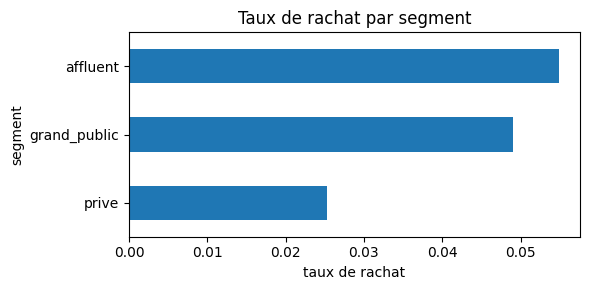

In [8]:
import matplotlib.pyplot as plt

taux_seg = df.groupby("segment").rachat_12m.mean().sort_values()
taux_seg.plot.barh(figsize=(6, 3), title="Taux de rachat par segment")
plt.xlabel("taux de rachat"); plt.tight_layout(); plt.show()

## 6. Ce que vous savez maintenant faire

✅ exécuter et relire un notebook · ✅ charger un CSV · ✅ détecter doublons et manquantes ·
✅ agréger par segment · ✅ produire un graphique.

**Règles d'or (mémo) :** exécuter les cellules **dans l'ordre** · une transformation = une cellule
commentée · graine aléatoire fixée · sauvegarder le notebook exécuté avec ses sorties.